# INSTALL REQUIRED PACKAGES

In [52]:
!pip install -q datasets scikit-learn pandas numpy
!pip install -q matplotlib seaborn
!pip install -q nltk sumy joblib streamlit
!pip install -q pymupdf requests

import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("All required libraries installed successfully!")


All required libraries installed successfully!


# LOAD THE LegalSeg DATASET

In [53]:
from datasets import load_dataset

dataset = load_dataset("L-NLProc/LegalSeg_CSV")

print("Dataset loaded successfully!")

print("\nDataset structure:")
print(dataset)

print("\nAvailable splits:")
print(dataset.keys())

for split in dataset.keys():
    print(split, ":", len(dataset[split]), "records")


Dataset loaded successfully!

Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['Index', 'Text', 'Label'],
        num_rows: 1122507
    })
    validation: Dataset({
        features: ['Index', 'Text', 'Label'],
        num_rows: 293370
    })
    test: Dataset({
        features: ['Index', 'Text', 'Label'],
        num_rows: 149881
    })
})

Available splits:
dict_keys(['train', 'validation', 'test'])
train : 1122507 records
validation : 293370 records
test : 149881 records


# DATASET PREPROCESSING

In [54]:
import pandas as pd
import numpy as np

# Convert all splits into DataFrames
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Original dataset sizes:")
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)


# Remove records without labels or text
def clean_dataset(df):

    df = df.dropna(subset=["Text", "Label"]).copy()

    df["Text"] = df["Text"].astype(str).str.strip()
    df["Label"] = df["Label"].astype(str).str.strip()

    # Remove empty text
    df = df[df["Text"] != ""]

    return df.reset_index(drop=True)


train_df_clean = clean_dataset(train_df)
val_df_clean = clean_dataset(val_df)
test_df_clean = clean_dataset(test_df)


print("\nCleaned dataset sizes:")
print("Train:", len(train_df_clean))
print("Validation:", len(val_df_clean))
print("Test:", len(test_df_clean))


# Identify actual classification labels
labels = sorted(train_df_clean["Label"].unique())

print("\nClassification labels:")
for label in labels:
    print("-", label)

print("\nTotal classes:", len(labels))


# Label distribution
print("\nTraining label distribution:")
print(train_df_clean["Label"].value_counts())

print("\nMissing values:")
print(train_df_clean.isnull().sum())


Original dataset sizes:
Train: (1122507, 3)
Validation: (293370, 3)
Test: (149881, 3)

Cleaned dataset sizes:
Train: 519388
Validation: 171652
Test: 91372

Classification labels:
- Arguments of Petitioner
- Arguments of Respondent
- Decision
- Facts
- Issue
- Reasoning

Total classes: 6

Training label distribution:
Label
Reasoning                  202328
Facts                      169647
Arguments of Petitioner     64985
Arguments of Respondent     50088
Decision                    19571
Issue                       12769
Name: count, dtype: int64

Missing values:
Index    0
Text     0
Label    0
dtype: int64


# DATA VISUALIZATION

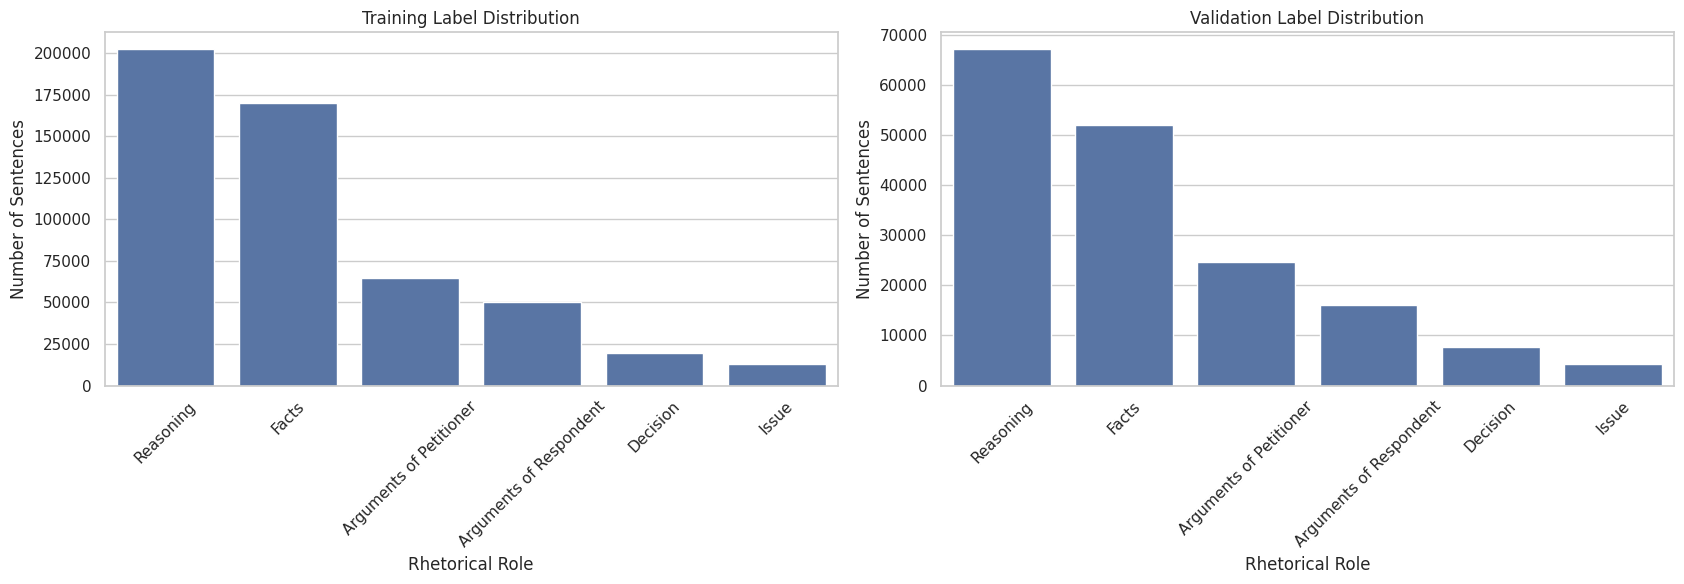


Class distribution in percentage:


,proportion
Label,
Reasoning,38.96
Facts,32.66
Arguments of Petitioner,12.51
Arguments of Respondent,9.64
Decision,3.77
Issue,2.46


In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Training distribution
sns.countplot(
    data=train_df_clean,
    x="Label",
    order=train_df_clean["Label"].value_counts().index,
    ax=axes[0]
)

axes[0].set_title("Training Label Distribution")
axes[0].set_xlabel("Rhetorical Role")
axes[0].set_ylabel("Number of Sentences")
axes[0].tick_params(axis="x", rotation=45)

# Validation distribution
sns.countplot(
    data=val_df_clean,
    x="Label",
    order=train_df_clean["Label"].value_counts().index,
    ax=axes[1]
)

axes[1].set_title("Validation Label Distribution")
axes[1].set_xlabel("Rhetorical Role")
axes[1].set_ylabel("Number of Sentences")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Percentage distribution
distribution = (
    train_df_clean["Label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nClass distribution in percentage:")
display(distribution)


# CREATE TRAINING AND VALIDATION SPLITS

In [56]:
train_split = train_df_clean.copy()
val_split = val_df_clean.copy()
test_split = test_df_clean.copy()

print("Final dataset sizes:")
print("Training:", len(train_split))
print("Validation:", len(val_split))
print("Testing:", len(test_split))


# Check document ID overlap
train_ids = set(train_split["Index"].unique())
val_ids = set(val_split["Index"].unique())
test_ids = set(test_split["Index"].unique())

print("\nDocument ID overlap:")
print("Train-Validation:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Validation-Test:", len(val_ids & test_ids))


if (
    len(train_ids & val_ids) == 0
    and len(train_ids & test_ids) == 0
    and len(val_ids & test_ids) == 0
):
    print("\nNo document ID overlap detected.")
else:
    print("\nWARNING: Document IDs overlap.")
    print("Verify what the Index column represents before")
    print("claiming document-level separation.")


Final dataset sizes:
Training: 519388
Validation: 171652
Testing: 91372

Document ID overlap:
Train-Validation: 0
Train-Test: 0
Validation-Test: 0

No document ID overlap detected.


# TF-IDF FEATURE EXTRACTION

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF configuration
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=50000,
    min_df=3,
    max_df=0.95,
    sublinear_tf=True,
    strip_accents="unicode"
)

print("Creating TF-IDF features...")

X_train = tfidf.fit_transform(train_split["Text"])

X_val = tfidf.transform(val_split["Text"])

print("\nTF-IDF feature extraction completed!")

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))


Creating TF-IDF features...

TF-IDF feature extraction completed!
Training matrix: (519388, 50000)
Validation matrix: (171652, 50000)
Vocabulary size: 50000


# MODEL COMPARISON

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report
)

import time

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        C=1.0,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.5
    )
}

results = []
trained_models = {}

for name, classifier in models.items():

    print("\n" + "=" * 55)
    print("Training:", name)
    print("=" * 55)

    start = time.time()

    classifier.fit(X_train, train_split["Label"])

    predictions = classifier.predict(X_val)

    accuracy = accuracy_score(
        val_split["Label"], predictions
    )

    macro_f1 = f1_score(
        val_split["Label"],
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        val_split["Label"],
        predictions,
        average="weighted",
        zero_division=0
    )

    precision = precision_score(
        val_split["Label"],
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        val_split["Label"],
        predictions,
        average="macro",
        zero_division=0
    )

    elapsed = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Training Time (seconds)": round(elapsed, 2)
    })

    trained_models[name] = classifier

    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Time:", round(elapsed, 2), "seconds")


# Display comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("\nFINAL MODEL COMPARISON:")
display(results_df)



Training: Logistic Regression
Accuracy: 0.5776
Macro F1: 0.5275
Time: 283.68 seconds

Training: Linear SVM
Accuracy: 0.6087
Macro F1: 0.5514
Time: 335.12 seconds

Training: Multinomial Naive Bayes
Accuracy: 0.5864
Macro F1: 0.483
Time: 4.5 seconds

FINAL MODEL COMPARISON:


,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Training Time (seconds)
1,Linear SVM,0.608726,0.551395,0.611111,0.527562,0.593259,335.12
0,Logistic Regression,0.577640,0.527452,0.587515,0.496265,0.613793,283.68
2,Multinomial Naive Bayes,0.586425,0.482990,0.557980,0.621596,0.446140,4.50


# MODEL PERFORMANCE COMPARISON

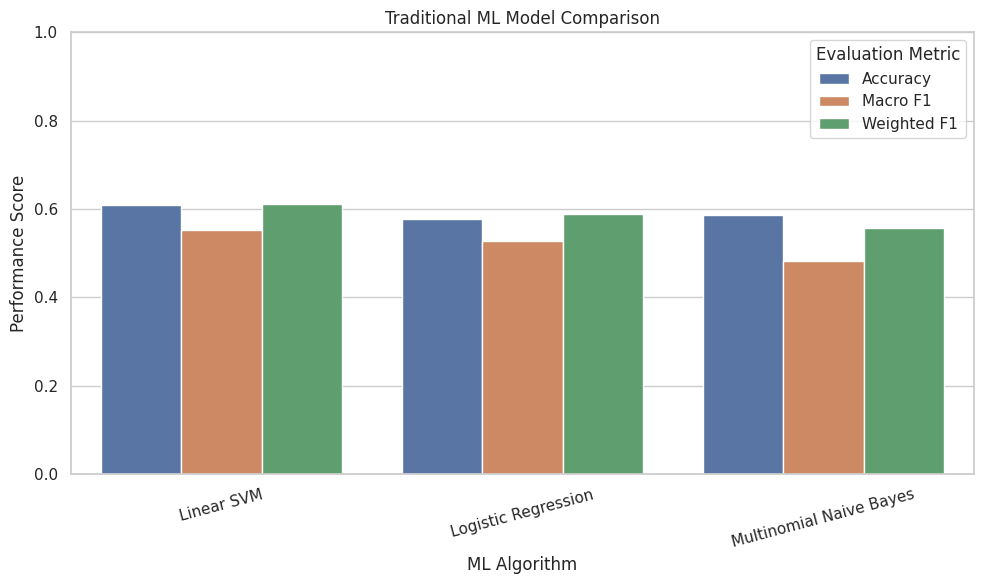

In [59]:
plt.figure(figsize=(10, 6))

comparison = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Macro F1",
        "Weighted F1"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=comparison,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Traditional ML Model Comparison")
plt.ylabel("Performance Score")
plt.xlabel("ML Algorithm")

plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title="Evaluation Metric")

plt.tight_layout()
plt.show()


# SELECT BEST MODEL

In [60]:
best_model_name = results_df.iloc[0]["Model"]

best_classifier = trained_models[best_model_name]

print("Best model:", best_model_name)

print("\nBest validation performance:")

display(
    results_df[
        results_df["Model"] == best_model_name
    ]
)

print("\nClassification report:")

val_predictions = best_classifier.predict(X_val)

print(
    classification_report(
        val_split["Label"],
        val_predictions,
        zero_division=0
    )
)


Best model: Linear SVM

Best validation performance:


,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall,Training Time (seconds)
1,Linear SVM,0.608726,0.551395,0.611111,0.527562,0.593259,335.12



Classification report:
                         precision    recall  f1-score   support

Arguments of Petitioner       0.50      0.48      0.49     24707
Arguments of Respondent       0.38      0.40      0.39     16020
               Decision       0.55      0.76      0.63      7634
                  Facts       0.64      0.70      0.67     51922
                  Issue       0.36      0.60      0.45      4257
              Reasoning       0.74      0.62      0.67     67112

               accuracy                           0.61    171652
              macro avg       0.53      0.59      0.55    171652
           weighted avg       0.62      0.61      0.61    171652



# TF-IDF FEATURE EXPERIMENTS

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Use a smaller stratified subset for experimentation
exp_train, _ = train_test_split(
    train_split,
    train_size=100000,
    stratify=train_split["Label"],
    random_state=42
)

exp_val, _ = train_test_split(
    val_split,
    train_size=25000,
    stratify=val_split["Label"],
    random_state=42
)

feature_configs = {
    "Unigram": TfidfVectorizer(
        ngram_range=(1, 1),
        max_features=30000,
        min_df=3,
        sublinear_tf=True
    ),

    "Unigram + Bigram": TfidfVectorizer(
        ngram_range=(1, 2),
        max_features=40000,
        min_df=3,
        sublinear_tf=True
    ),

    "Character N-gram": TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        max_features=30000,
        min_df=3,
        sublinear_tf=True
    )
}

feature_results = []

for name, vectorizer in feature_configs.items():

    print("\nTesting:", name)

    X_tr = vectorizer.fit_transform(exp_train["Text"])
    X_va = vectorizer.transform(exp_val["Text"])

    clf = LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42
    )

    clf.fit(X_tr, exp_train["Label"])

    pred = clf.predict(X_va)

    score = f1_score(
        exp_val["Label"],
        pred,
        average="macro",
        zero_division=0
    )

    feature_results.append({
        "Feature Method": name,
        "Macro F1": score,
        "Vocabulary Size": len(vectorizer.vocabulary_)
    })

    print("Macro F1:", round(score, 4))

feature_results_df = pd.DataFrame(feature_results)

display(
    feature_results_df.sort_values(
        "Macro F1",
        ascending=False
    )
)



Testing: Unigram
Macro F1: 0.4649

Testing: Unigram + Bigram
Macro F1: 0.5044

Testing: Character N-gram
Macro F1: 0.4778


,Feature Method,Macro F1,Vocabulary Size
1,Unigram + Bigram,0.504433,40000
2,Character N-gram,0.477849,30000
0,Unigram,0.464893,20310


# FINAL MODEL TRAINING

In [62]:
from sklearn.pipeline import Pipeline

# Create the selected classifier
final_classifier = models[best_model_name]

# Build complete pipeline
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=50000,
            min_df=3,
            max_df=0.95,
            sublinear_tf=True,
            strip_accents="unicode"
        )
    ),

    ("classifier", final_classifier)
])

print("Training final model on full training dataset...")

start_time = time.time()

model.fit(
    train_split["Text"],
    train_split["Label"]
)

training_time = time.time() - start_time

print("\nFinal model training completed!")

print("Selected model:", best_model_name)
print("Training time:", round(training_time, 2), "seconds")
print("Classes:", model.classes_)


Training final model on full training dataset...

Final model training completed!
Selected model: Linear SVM
Training time: 398.06 seconds
Classes: ['Arguments of Petitioner' 'Arguments of Respondent' 'Decision' 'Facts'
 'Issue' 'Reasoning']


# VALIDATION EVALUATION

In [63]:
from sklearn.metrics import classification_report

val_predictions = model.predict(val_split["Text"])

val_accuracy = accuracy_score(
    val_split["Label"],
    val_predictions
)

val_macro_f1 = f1_score(
    val_split["Label"],
    val_predictions,
    average="macro"
)

print("VALIDATION RESULTS")
print("=" * 50)

print("Accuracy:", round(val_accuracy, 4))
print("Macro F1:", round(val_macro_f1, 4))

print("\nClassification Report:")

print(
    classification_report(
        val_split["Label"],
        val_predictions,
        zero_division=0
    )
)


VALIDATION RESULTS
Accuracy: 0.6087
Macro F1: 0.5514

Classification Report:
                         precision    recall  f1-score   support

Arguments of Petitioner       0.50      0.48      0.49     24707
Arguments of Respondent       0.38      0.40      0.39     16020
               Decision       0.55      0.76      0.63      7634
                  Facts       0.64      0.70      0.67     51922
                  Issue       0.36      0.60      0.45      4257
              Reasoning       0.74      0.62      0.67     67112

               accuracy                           0.61    171652
              macro avg       0.53      0.59      0.55    171652
           weighted avg       0.62      0.61      0.61    171652



# FINAL TEST EVALUATION

In [64]:
test_predictions = model.predict(test_split["Text"])

test_accuracy = accuracy_score(
    test_split["Label"],
    test_predictions
)

test_macro_f1 = f1_score(
    test_split["Label"],
    test_predictions,
    average="macro"
)

test_weighted_f1 = f1_score(
    test_split["Label"],
    test_predictions,
    average="weighted"
)

print("FINAL TEST RESULTS")
print("=" * 50)

print("Accuracy:", round(test_accuracy, 4))
print("Macro F1:", round(test_macro_f1, 4))
print("Weighted F1:", round(test_weighted_f1, 4))

print("\nDetailed classification report:")

print(
    classification_report(
        test_split["Label"],
        test_predictions,
        zero_division=0
    )
)


FINAL TEST RESULTS
Accuracy: 0.5446
Macro F1: 0.4691
Weighted F1: 0.5449

Detailed classification report:
                         precision    recall  f1-score   support

Arguments of Petitioner       0.43      0.38      0.40     14520
Arguments of Respondent       0.30      0.30      0.30      9579
               Decision       0.53      0.59      0.56      3841
                  Facts       0.54      0.71      0.62     24908
                  Issue       0.25      0.40      0.31      1836
              Reasoning       0.70      0.56      0.63     36688

               accuracy                           0.54     91372
              macro avg       0.46      0.49      0.47     91372
           weighted avg       0.56      0.54      0.54     91372



# VISUALIZE CONFUSION MATRIX

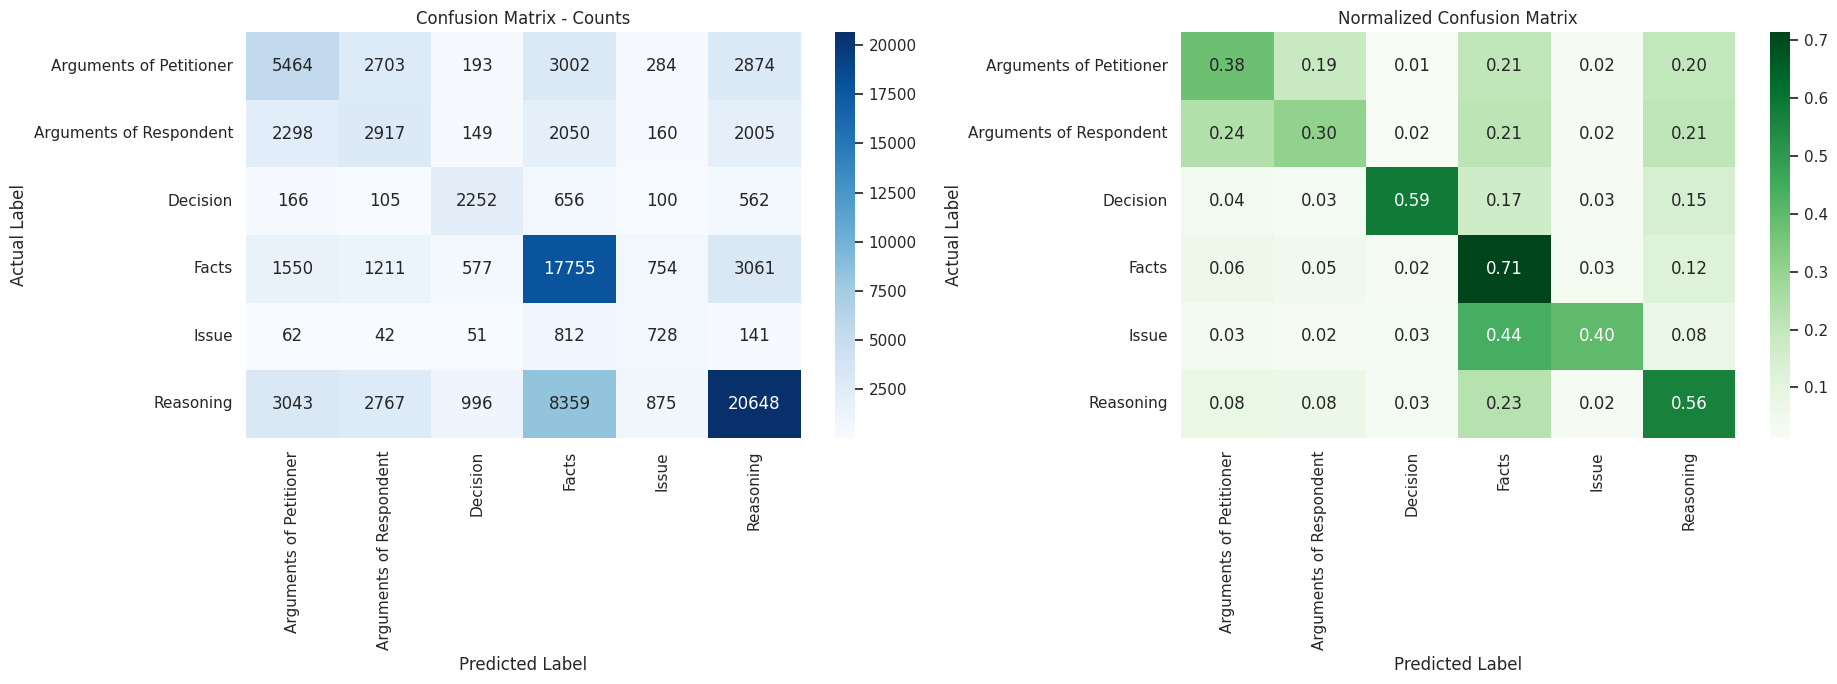

In [65]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_split["Label"],
    test_predictions,
    labels=model.classes_
)

fig, axes = plt.subplots(1, 2, figsize=(19, 7))

# Raw confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    ax=axes[0]
)

axes[0].set_title("Confusion Matrix - Counts")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Normalized confusion matrix
cm_normalized = cm / cm.sum(axis=1, keepdims=True)

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Greens",
    xticklabels=model.classes_,
    yticklabels=model.classes_,
    ax=axes[1]
)

axes[1].set_title("Normalized Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


# SAVE FINAL MODEL

In [66]:
import joblib

joblib.dump(
    model,
    "best_role_classifier.pkl"
)

joblib.dump(
    list(model.classes_),
    "role_labels.pkl"
)

model_info = {
    "model_name": best_model_name,
    "validation_accuracy": val_accuracy,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_weighted_f1": test_weighted_f1,
    "classes": list(model.classes_)
}

joblib.dump(model_info, "model_info.pkl")

print("Model saved successfully!")

print("\nSaved files:")
print("1. best_role_classifier.pkl")
print("2. role_labels.pkl")
print("3. model_info.pkl")

print("\nFinal test accuracy:", round(test_accuracy * 100, 2), "%")
print("Final test macro F1:", round(test_macro_f1, 4))


Model saved successfully!

Saved files:
1. best_role_classifier.pkl
2. role_labels.pkl
3. model_info.pkl

Final test accuracy: 54.46 %
Final test macro F1: 0.4691


# SAMPLE LEGAL TEXT PREDICTIONS

In [67]:
sample_texts = [
    "The petitioner filed the present appeal challenging the order of the lower court.",

    "The respondent argued that the appeal was not maintainable.",

    "Whether the impugned order violates Article 14 of the Constitution of India?",

    "The learned counsel for the petitioner argued that the procedure was not followed.",

    "We find that the principles of natural justice were indeed violated in this case.",

    "Accordingly, the appeal is allowed and the impugned order is set aside.",

    "The facts of the case indicate a clear breach of contract by the defendant."
]

sample_predictions = model.predict(sample_texts)

# Get probability or decision scores
if hasattr(model, "predict_proba"):

    sample_scores = model.predict_proba(sample_texts).max(axis=1)
    score_name = "Confidence (probability)"

else:

    sample_scores = model.decision_function(sample_texts)

    if sample_scores.ndim == 1:
        sample_scores = np.abs(sample_scores)
    else:
        sample_scores = sample_scores.max(axis=1)

    score_name = "Decision margin (not probability)"


sample_results = pd.DataFrame({
    "Sentence": sample_texts,
    "Predicted Role": sample_predictions,
    score_name: np.round(sample_scores, 4)
})

display(sample_results)


,Sentence,Predicted Role,Decision margin (not probability)
0,The petitioner filed the present appeal challe...,Facts,0.6654
1,The respondent argued that the appeal was not ...,Arguments of Respondent,0.1859
2,Whether the impugned order violates Article 14...,Issue,1.1344
3,The learned counsel for the petitioner argued ...,Arguments of Petitioner,0.6747
4,We find that the principles of natural justice...,Reasoning,1.2937
5,"Accordingly, the appeal is allowed and the imp...",Decision,1.8913
6,The facts of the case indicate a clear breach ...,Reasoning,-0.1162


# REUSABLE PREDICTION FUNCTION

In [68]:
def predict_rhetorical_roles(texts):

    if isinstance(texts, str):
        texts = [texts]

    texts = [str(t).strip() for t in texts if str(t).strip()]

    if not texts:
        return pd.DataFrame(
            columns=["Text", "Predicted Role"]
        )

    predictions = model.predict(texts)

    output = pd.DataFrame({
        "Text": texts,
        "Predicted Role": predictions
    })

    # Add probabilities when supported
    if hasattr(model, "predict_proba"):

        probabilities = model.predict_proba(texts)

        output["Confidence"] = np.round(
            probabilities.max(axis=1), 4
        )

    else:

        scores = model.decision_function(texts)

        if scores.ndim == 1:
            margins = np.abs(scores)
        else:
            margins = scores.max(axis=1)

        output["Decision Margin"] = np.round(
            margins, 4
        )

    return output


# Test function
result = predict_rhetorical_roles(
    "The court finds that the appeal has no merit."
)

display(result)


,Text,Predicted Role,Decision Margin
0,The court finds that the appeal has no merit.,Reasoning,-0.2949


# ERROR ANALYSIS

In [69]:
error_df = test_split[
    ["Text", "Label"]
].copy()

error_df["Predicted Label"] = test_predictions

error_df["Correct"] = (
    error_df["Label"] == error_df["Predicted Label"]
)

# Extract incorrectly classified sentences
misclassified = error_df[
    error_df["Correct"] == False
].copy()

print("Total incorrect predictions:", len(misclassified))

print("\nMost frequent classification errors:")

error_counts = (
    misclassified.groupby(
        ["Label", "Predicted Label"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(error_counts.head(15))

print("\nExample misclassified sentences:")

display(
    misclassified[
        ["Text", "Label", "Predicted Label"]
    ].head(20)
)


Total incorrect predictions: 41608

Most frequent classification errors:


,Label,Predicted Label,Count
28,Reasoning,Facts,8359
19,Facts,Reasoning,3061
25,Reasoning,Arguments of Petitioner,3043
2,Arguments of Petitioner,Facts,3002
4,Arguments of Petitioner,Reasoning,2874
26,Reasoning,Arguments of Respondent,2767
0,Arguments of Petitioner,Arguments of Respondent,2703
5,Arguments of Respondent,Arguments of Petitioner,2298
7,Arguments of Respondent,Facts,2050
9,Arguments of Respondent,Reasoning,2005



Example misclassified sentences:


,Text,Label,Predicted Label
8,It has been submitted on behalf of the appella...,Facts,Arguments of Petitioner
30,"On behalf of the Corporate Debtor, it is submi...",Facts,Arguments of Petitioner
33,The Corporate Debtor has further submitted tha...,Facts,Arguments of Respondent
36,The Corporate Debtor has further submitted tha...,Facts,Arguments of Petitioner
39,Proceedings before the NCLT and NCLAT 11.,Facts,Arguments of Petitioner
42,The NCLT observed that prima facie it appeared...,Facts,Reasoning
43,The conclusion of the NCLT is extracted below ...,Facts,Reasoning
44,"In this scenario, we are of the prima facie vi...",Facts,Reasoning
45,"In view of the same, we hereby stay the termin...",Facts,Decision
46,Until then the respondent shall adhere to the ...,Facts,Decision


# INSTALL STREAMLIT APPLICATION DEPENDENCIES

In [70]:
!pip install -q streamlit pymupdf nltk sumy joblib

import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Application dependencies ready!")


Application dependencies ready!


# CREATE THE STREAMLIT APP FILE

In [71]:

%%writefile app.py

import streamlit as st
import joblib
import pandas as pd
import nltk
import re
import fitz

from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer


# ==========================================
# 1. PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Indian Court Judgment Analyzer",
    page_icon="⚖️",
    layout="wide"
)

st.title("⚖️ Indian Court Judgment Analyzer")

st.markdown(
    """
    Analyze Indian court judgments using traditional
    Natural Language Processing and Machine Learning.

    **Techniques:** TF-IDF, Machine Learning, NER and TextRank.
    """
)

st.warning(
    "Educational research tool only. "
    "Predictions and summaries are experimental "
    "and must not be treated as legal advice."
)


# ==========================================
# 2. LOAD TRAINED MODEL
# ==========================================

@st.cache_resource
def load_model():

    model = joblib.load("best_role_classifier.pkl")

    labels = joblib.load("role_labels.pkl")

    info = joblib.load("model_info.pkl")

    return model, labels, info


model, labels, model_info = load_model()


# ==========================================
# 3. TEXT EXTRACTION
# ==========================================

def extract_text(uploaded_file):

    if uploaded_file.name.lower().endswith(".txt"):

        return uploaded_file.read().decode(
            "utf-8", errors="replace"
        )

    elif uploaded_file.name.lower().endswith(".pdf"):

        pdf = fitz.open(
            stream=uploaded_file.read(),
            filetype="pdf"
        )

        pages = []

        for page in pdf:
            pages.append(page.get_text())

        pdf.close()

        return "\n".join(pages)

    return ""


# ==========================================
# 4. LEGAL ENTITY EXTRACTION
# ==========================================

def extract_legal_entities(text):

    entities = {
        "Statutes": set(),
        "Courts": set(),
        "Sections and Articles": set(),
        "Dates": set(),
        "Judges": set()
    }

    statute_patterns = [
        r"\bIndian Penal Code\b",
        r"\bCode of Criminal Procedure\b",
        r"\bCode of Civil Procedure\b",
        r"\bIndian Evidence Act\b",
        r"\bConstitution of India\b",
        r"\bNDPS Act\b",
        r"\b[A-Z][A-Za-z ]+ Act,?\s+\d{4}\b"
    ]

    court_patterns = [
        r"\bSupreme Court of India\b",
        r"\b[A-Z][A-Za-z ]+ High Court\b",
        r"\bDistrict Court\b"
    ]

    section_patterns = [
        r"\b(?:Section|Sections|Article|Articles|Order)"
        r"\s+\d+[A-Z]?(?:\(\d+\))*"
    ]

    date_patterns = [
        r"\b\d{1,2}[./-]\d{1,2}[./-]\d{2,4}\b",
        r"\b(?:January|February|March|April|May|June|"
        r"July|August|September|October|November|December)"
        r"\s+\d{1,2},?\s+\d{4}\b"
    ]

    judge_patterns = [
        r"\bJustice\s+[A-Z][A-Za-z. ]+",
        r"\bJ\.\s*[A-Z][A-Za-z. ]+"
    ]

    for pattern in statute_patterns:
        entities["Statutes"].update(
            re.findall(pattern, text, re.IGNORECASE)
        )

    for pattern in court_patterns:
        entities["Courts"].update(
            re.findall(pattern, text, re.IGNORECASE)
        )

    for pattern in section_patterns:
        entities["Sections and Articles"].update(
            re.findall(pattern, text, re.IGNORECASE)
        )

    for pattern in date_patterns:
        entities["Dates"].update(
            re.findall(pattern, text, re.IGNORECASE)
        )

    for pattern in judge_patterns:
        entities["Judges"].update(
            re.findall(pattern, text, re.IGNORECASE)
        )

    return {
        key: sorted(value) for key, value in entities.items()
    }


# ==========================================
# 5. TEXTRANK SUMMARIZATION
# ==========================================

def summarize_text(text, sentence_count=5):

    try:

        parser = PlaintextParser.from_string(
            text,
            Tokenizer("english")
        )

        summarizer = TextRankSummarizer()

        summary = summarizer(
            parser.document,
            sentence_count
        )

        return [str(sentence) for sentence in summary]

    except Exception:
        return []


# ==========================================
# 6. ROLE-BASED SUMMARIZATION
# ==========================================

def summarize_by_role(df):

    summaries = {}

    for role in df["Predicted Role"].unique():

        role_text = " ".join(
            df.loc[
                df["Predicted Role"] == role,
                "Sentence"
            ].tolist()
        )

        summary = summarize_text(
            role_text,
            sentence_count=3
        )

        if summary:
            summaries[role] = summary

    return summaries


# ==========================================
# 7. SIDEBAR
# ==========================================

st.sidebar.header("Document Upload")

uploaded_file = st.sidebar.file_uploader(
    "Upload a court judgment",
    type=["txt", "pdf"]
)

st.sidebar.divider()

st.sidebar.subheader("Model Information")

st.sidebar.write(
    "**Selected model:**",
    model_info["model_name"]
)

st.sidebar.write(
    "**Test accuracy:**",
    f'{model_info["test_accuracy"] * 100:.2f}%'
)

st.sidebar.write(
    "**Test Macro F1:**",
    f'{model_info["test_macro_f1"]:.4f}'
)


# ==========================================
# 8. MAIN APPLICATION
# ==========================================

if uploaded_file is not None:

    judgment_text = extract_text(uploaded_file)

    if not judgment_text.strip():

        st.error(
            "No readable text found. "
            "Scanned PDFs may require OCR."
        )

    else:

        with st.spinner("Analyzing court judgment..."):

            sentences = nltk.sent_tokenize(
                judgment_text
            )

            sentences = [
                sentence.strip()
                for sentence in sentences
                if sentence.strip()
            ]

            if not sentences:
                st.error("No sentences could be extracted.")

            else:

                predictions = model.predict(sentences)

                df_results = pd.DataFrame({
                    "Sentence": sentences,
                    "Predicted Role": predictions
                })

                # Get probability or decision margin
                if hasattr(model, "predict_proba"):

                    scores = model.predict_proba(
                        sentences
                    ).max(axis=1)

                    df_results["Model Score"] = scores

                    score_label = "Model score (probability)"

                else:

                    scores = model.decision_function(
                        sentences
                    )

                    if scores.ndim == 1:
                        scores = abs(scores)
                    else:
                        scores = scores.max(axis=1)

                    df_results["Model Score"] = scores

                    score_label = "Decision margin (not probability)"

                entities = extract_legal_entities(
                    judgment_text
                )

                overall_summary = summarize_text(
                    judgment_text,
                    sentence_count=5
                )

                role_summaries = summarize_by_role(
                    df_results
                )


                # ==================================
                # 9. DOCUMENT STATISTICS
                # ==================================

                st.header("Document Overview")

                col1, col2, col3 = st.columns(3)

                col1.metric(
                    "Total Sentences",
                    len(sentences)
                )

                col2.metric(
                    "Word Count",
                    len(judgment_text.split())
                )

                col3.metric(
                    "Detected Roles",
                    df_results["Predicted Role"].nunique()
                )

                st.divider()


                # ==================================
                # 10. OVERALL SUMMARY
                # ==================================

                st.header("Extractive Summary")

                if overall_summary:

                    for i, sentence in enumerate(
                        overall_summary, 1
                    ):
                        st.write(f"{i}. {sentence}")

                else:
                    st.info("Summary could not be generated.")


                st.divider()


                # ==================================
                # 11. ROLE-BASED SUMMARY
                # ==================================

                st.header("Role-Based Summarization")

                for role, summary in role_summaries.items():

                    with st.expander(role):

                        for i, sentence in enumerate(
                            summary, 1
                        ):
                            st.write(f"{i}. {sentence}")


                st.divider()


                # ==================================
                # 12. ENTITY EXTRACTION
                # ==================================

                st.header("Legal Named Entities")

                cols = st.columns(2)

                for i, (entity, values) in enumerate(
                    entities.items()
                ):

                    with cols[i % 2]:

                        st.subheader(entity)

                        if values:
                            for value in values:
                                st.write("•", value)
                        else:
                            st.write("None detected")


                st.divider()


                # ==================================
                # 13. ROLE DISTRIBUTION
                # ==================================

                st.header("Rhetorical Role Distribution")

                role_counts = (
                    df_results["Predicted Role"]
                    .value_counts()
                    .reset_index()
                )

                role_counts.columns = [
                    "Role",
                    "Count"
                ]

                col1, col2 = st.columns(2)

                with col1:

                    st.bar_chart(
                        role_counts.set_index("Role")
                    )

                with col2:

                    st.dataframe(
                        role_counts,
                        use_container_width=True,
                        hide_index=True
                    )


                st.divider()


                # ==================================
                # 14. SENTENCE CLASSIFICATION
                # ==================================

                st.header("Sentence Classification")

                st.caption(
                    f"Score type: {score_label}"
                )

                selected_roles = st.multiselect(
                    "Filter by rhetorical role",
                    options=sorted(labels),
                    default=sorted(labels)
                )

                filtered_df = df_results[
                    df_results["Predicted Role"].isin(
                        selected_roles
                    )
                ]

                st.dataframe(
                    filtered_df,
                    use_container_width=True,
                    height=450
                )


                # ==================================
                # 15. DOWNLOAD RESULTS
                # ==================================

                csv_data = df_results.to_csv(
                    index=False
                ).encode("utf-8")

                st.download_button(
                    label="Download Classification Results",
                    data=csv_data,
                    file_name="legal_analysis.csv",
                    mime="text/csv"
                )

else:

    st.info(
        "Upload a court judgment in PDF or TXT format "
        "using the sidebar to begin analysis."
    )


Overwriting app.py


# DEPLOY STREAMLIT

In [72]:
import subprocess
import time
import os
import re
import requests
import shutil

# Install Cloudflare only if not installed
if shutil.which("cloudflared") is None:

    print("Installing Cloudflare Tunnel...")

    subprocess.run([
        "wget", "-q", "-O", "cloudflared.deb",
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb"
    ], check=True)

    subprocess.run(
        ["dpkg", "-i", "cloudflared.deb"],
        check=True
    )

# Start Streamlit
print("\nStarting Streamlit...")

streamlit_log = open("/tmp/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=streamlit_log,
    stderr=subprocess.STDOUT
)

# Check application health
ready = False

for i in range(30):

    try:

        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )

        if response.status_code == 200:
            ready = True
            break

    except requests.RequestException:
        pass

    if streamlit_process.poll() is not None:
        break

    time.sleep(1)


if not ready:

    print("Streamlit failed to start.")

    streamlit_log.flush()

    with open("/tmp/streamlit.log") as f:
        print(f.read()[-3000:])

else:

    print("Streamlit is running!")

    # Remove previous tunnel log
    tunnel_log = "/tmp/cloudflared.log"

    if os.path.exists(tunnel_log):
        os.remove(tunnel_log)

    # Start Cloudflare
    tunnel_process = subprocess.Popen(
        [
            "cloudflared",
            "tunnel",
            "--url", "http://localhost:8501",
            "--no-autoupdate",
            "--logfile", tunnel_log,
            "--loglevel", "info"
        ],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )

    # Wait for public URL
    public_url = None

    for i in range(60):

        if tunnel_process.poll() is not None:
            break

        if os.path.exists(tunnel_log):

            with open(tunnel_log) as f:
                logs = f.read()

            match = re.search(
                r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
                logs
            )

            if match:
                public_url = match.group(0)
                break

        time.sleep(1)


    if public_url:

        print("\nSUCCESS!")
        print("Your application is live:")
        print(public_url)

        print("\nKeep the Colab runtime running.")

    else:

        print("Tunnel URL was not generated.")

        if os.path.exists(tunnel_log):
            with open(tunnel_log) as f:
                print(f.read()[-3000:])



Starting Streamlit...
Streamlit is running!

SUCCESS!
Your application is live:
https://delays-requires-organised-fed.trycloudflare.com

Keep the Colab runtime running.
